In [1]:
# Import required libraries for data analysis and visualization
import os, glob, pandas as pd, seaborn as sns, numpy as np, matplotlib.pyplot as plt
from pathlib import Path

In [2]:
import re

# Load master heatmap CSV files from current directory
csv_files = glob.glob("master_heatmap*.csv")  # Find all CSV files in current directory

def extract_teff_bin(filename):
    match = re.search(r'(\d{4})_(\d{4})_K', filename)
    if match:
        return f"{match.group(1)}_{match.group(2)}"
    return None

# Load and combine all CSV files into a single dataframe, adding temperature bin
df = pd.DataFrame()
for f in csv_files:
    temp_bin = extract_teff_bin(f)
    temp_df = pd.read_csv(f)
    temp_df['teff_bin'] = temp_bin
    df = pd.concat([df, temp_df], ignore_index=True)

print(f"Combined dataframe shape: {df.shape}")
print(f"Columns: {list(df.columns)}")
print(df.head())



Combined dataframe shape: (336, 7)
Columns: ['radius_bin_center', 'period_bin_center', 'detections', 'trials', 'transit_prob', 'detection_rate', 'teff_bin']
   radius_bin_center  period_bin_center  detections  trials  transit_prob  \
0           1.923851           0.786000          36      41      0.224285   
1           1.923851           1.336168          25      32      0.159290   
2           1.923851           2.271888          24      29      0.109199   
3           1.923851           3.863276          29      42      0.081758   
4           1.923851           6.569863          22      36      0.055315   

   detection_rate   teff_bin  
0        0.878049  4000_4500  
1        0.781250  4000_4500  
2        0.827586  4000_4500  
3        0.690476  4000_4500  
4        0.611111  4000_4500  


Period values: [ 0.786       1.33616763  2.2718882   3.86327637  6.56986297 11.17286733
 18.99781387]
Period log values: [-0.10457745  0.12586095  0.35638696  0.58695578  0.81755631  1.04816464
  1.27870363]
Period bin edges: [0.6028417826212565, 1.0248062058899103, 1.7423040703393378, 2.9625887317403348, 5.037975426914379, 8.567625539322146, 14.56914733367361, 24.772687354491236]
Number of bins: 7


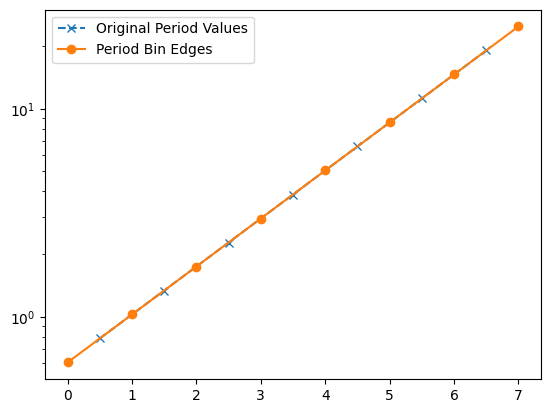

Radius values: [1.92385113 2.1977049  2.51054084 2.86790793 3.27614504 3.74249332]
Radius log values: [0.28417146 0.34196938 0.39976729 0.45756521 0.51536312 0.57316103]
Radius bin edges: [1.7999999999999998, 2.056223979157517, 2.348920584701318, 2.6832815729997477, 3.065237729574213, 3.501564067427134, 3.999999999999999]
Number of bins: 6


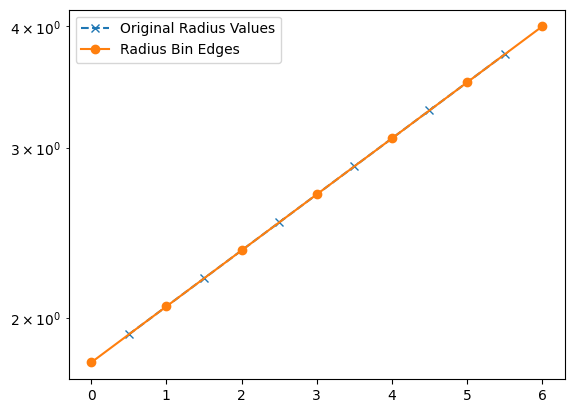

In [3]:
# Generate log-spaced bin edges for True Period values
period_vals = np.array(sorted(df['period_bin_center'].unique()))  # Get unique period values

# Calculate log-space halfway points between adjacent values
period_log = np.log10(period_vals)  # Convert to log space
period_bin_edges = []

# First edge: extrapolate backward using same log spacing as first interval
log_step = period_log[1] - period_log[0]  # Log spacing between first two values
first_edge = 10**(period_log[0] - log_step/2)  # Extrapolate backward by half step
period_bin_edges.append(first_edge)

# Middle edges: halfway points in log space between adjacent values
for i in range(len(period_log) - 1):
    halfway_log = (period_log[i] + period_log[i+1]) / 2  # Midpoint in log space
    period_bin_edges.append(10**halfway_log)  # Convert back to linear space

# Last edge: extrapolate forward using same log spacing as last interval
log_step = period_log[-1] - period_log[-2]  # Log spacing between last two values
last_edge = 10**(period_log[-1] + log_step/2)  # Extrapolate forward by half step
period_bin_edges.append(last_edge)

# Print results for verification
print(f"Period values: {period_vals}")
print(f"Period log values: {period_log}")
print(f"Period bin edges: {period_bin_edges}")
print(f"Number of bins: {len(period_bin_edges) - 1}")

# Plot to visualize period values vs bin edges
period_vals_x_axis = np.arange(len(period_vals)) + 0.5  # Offset for visualization
plt.plot(period_vals_x_axis, period_vals, 'x--', label='Original Period Values')
plt.plot(period_bin_edges, 'o-', label='Period Bin Edges')
plt.legend()
plt.yscale('log')  # Log scale for better visualization
plt.show()

# Generate log-spaced bin edges for True Radius values (same method as periods)
radius_vals = np.array(sorted(df['radius_bin_center'].unique()))  # Get unique radius values

# Calculate log-space halfway points between adjacent values
radius_log = np.log10(radius_vals)  # Convert to log space
radius_bin_edges = []

# First edge: extrapolate backward using same log spacing as first interval
log_step = radius_log[1] - radius_log[0]  # Log spacing between first two values
first_edge = 10**(radius_log[0] - log_step/2)  # Extrapolate backward by half step
radius_bin_edges.append(first_edge)

# Middle edges: halfway points in log space between adjacent values
for i in range(len(radius_log) - 1):
    halfway_log = (radius_log[i] + radius_log[i+1]) / 2  # Midpoint in log space
    radius_bin_edges.append(10**halfway_log)  # Convert back to linear space

# Last edge: extrapolate forward using same log spacing as last interval
log_step = radius_log[-1] - radius_log[-2]  # Log spacing between last two values
last_edge = 10**(radius_log[-1] + log_step/2)  # Extrapolate forward by half step
radius_bin_edges.append(last_edge)

# Print results for verification
print(f"Radius values: {radius_vals}")
print(f"Radius log values: {radius_log}")
print(f"Radius bin edges: {radius_bin_edges}")
print(f"Number of bins: {len(radius_bin_edges) - 1}")

# Plot to visualize radius values vs bin edges
radius_vals_x_axis = np.arange(len(radius_vals)) + 0.5  # Offset for visualization
plt.plot(radius_vals_x_axis, radius_vals, 'x--', label='Original Radius Values')
plt.plot(radius_bin_edges, 'o-', label='Radius Bin Edges')
plt.legend()
plt.yscale('log')  # Log scale for better visualization
plt.show()



In [4]:
# Assign bin min/max edges for each row using pd.cut with labels as bin index, then map to edge values
df['radius_bin'] = pd.cut(df['radius_bin_center'], bins=radius_bin_edges, include_lowest=True, labels=False)
df['period_bin'] = pd.cut(df['period_bin_center'], bins=period_bin_edges, include_lowest=True, labels=False)
df['radius_bin_min'] = df['radius_bin'].apply(lambda x: radius_bin_edges[int(x)] if pd.notnull(x) else np.nan)
df['radius_bin_max'] = df['radius_bin'].apply(lambda x: radius_bin_edges[int(x)+1] if pd.notnull(x) else np.nan)
df['period_bin_min'] = df['period_bin'].apply(lambda x: period_bin_edges[int(x)] if pd.notnull(x) else np.nan)
df['period_bin_max'] = df['period_bin'].apply(lambda x: period_bin_edges[int(x)+1] if pd.notnull(x) else np.nan)
print(df.head())

   radius_bin_center  period_bin_center  detections  trials  transit_prob  \
0           1.923851           0.786000          36      41      0.224285   
1           1.923851           1.336168          25      32      0.159290   
2           1.923851           2.271888          24      29      0.109199   
3           1.923851           3.863276          29      42      0.081758   
4           1.923851           6.569863          22      36      0.055315   

   detection_rate   teff_bin  radius_bin  period_bin  radius_bin_min  \
0        0.878049  4000_4500           0           0             1.8   
1        0.781250  4000_4500           0           1             1.8   
2        0.827586  4000_4500           0           2             1.8   
3        0.690476  4000_4500           0           3             1.8   
4        0.611111  4000_4500           0           4             1.8   

   radius_bin_max  period_bin_min  period_bin_max  
0        2.056224        0.602842        1.024806  


687


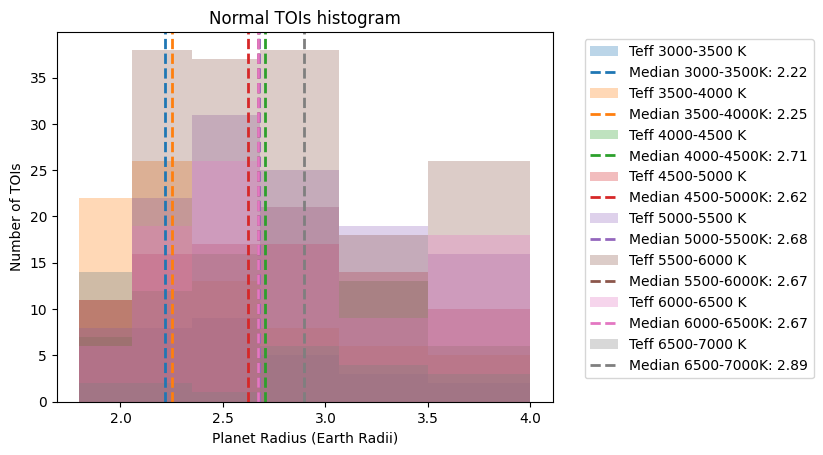

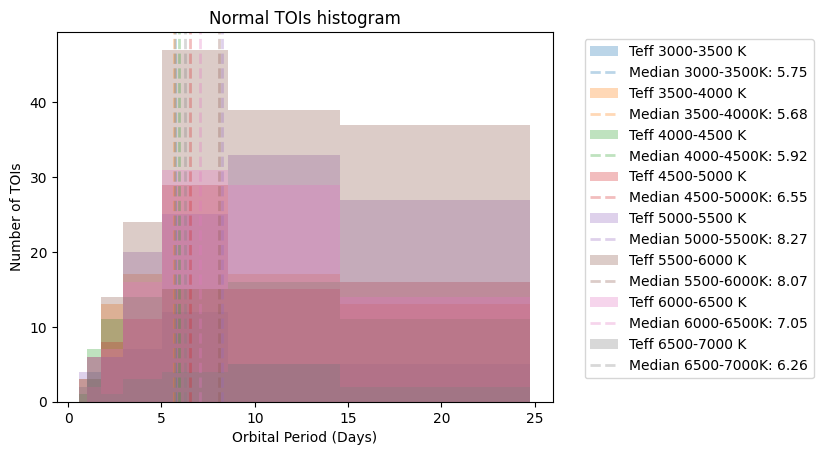

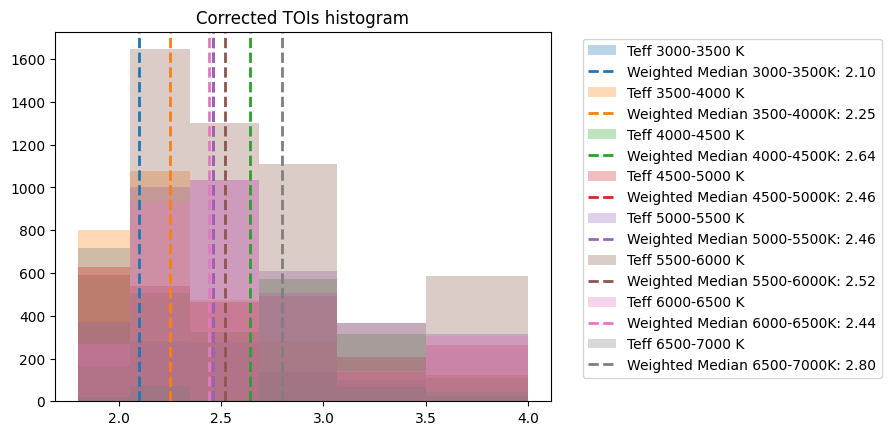

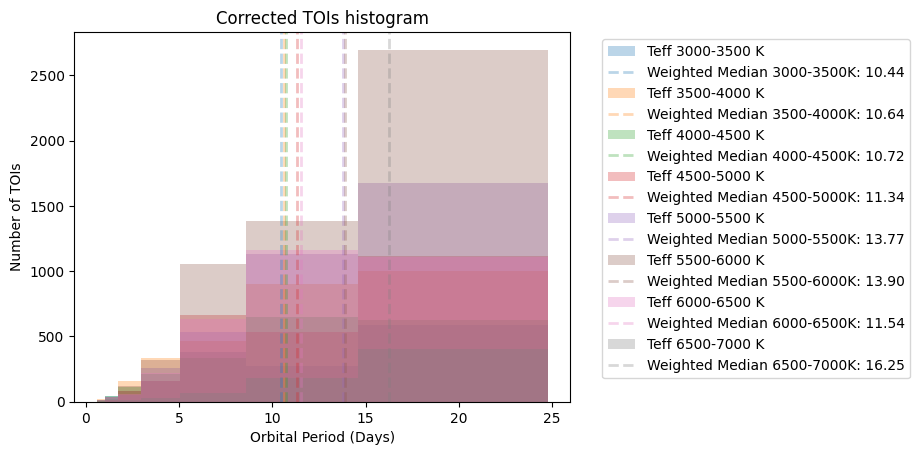

Rows with any NaNs in merged_df: 1
Rows with NaNs in merged_df:
         toi  st_teff  pl_rade  pl_orbper   teff_bin  radius_bin_min  \
612  1873.01   5699.0  3.93465  24.934188  5500_6000        3.501564   

     radius_bin_max  period_bin_min  period_bin_max  radius_bin_center  \
612             4.0             NaN             NaN                NaN   

     period_bin_center  detections  trials  transit_prob  detection_rate  \
612                NaN         NaN     NaN           NaN             NaN   

     radius_bin  period_bin  detection_inverse  transit_inverse  weight  
612         NaN         NaN                NaN              NaN     1.0  
         toi  st_teff   pl_rade  pl_orbper   teff_bin  radius_bin_min  \
0    5165.01  4642.10  3.300100   3.577501  4500_5000        3.065238   
1    6944.01  5181.10  2.609860  12.302750  5000_5500        2.348921   
2    5789.01  5132.00  2.537040  12.925605  5000_5500        2.348921   
3    5319.01  3580.00  3.746810   4.078527  3500_

In [5]:
 
TOIs = pd.read_csv('../TOI_Mar2025_1pt5to4_R_detected_real_only.csv')

# Define temperature ranges matching our completeness data
teff_ranges = [(3000, 3500), (3500, 4000), (4000, 4500), (4500, 5000), 
               (5000, 5500), (5500, 6000), (6000, 6500), (6500, 7000)]

#teff_ranges = [(t, t + 1000) for t in range(3000, 7000, 1000)]

# Filter TOIs data
TOIs_filtered = TOIs.dropna(subset=['st_teff', 'pl_rade'])
#print(len(TOIs_filtered))

TOIs_filtered = TOIs_filtered[(TOIs_filtered['pl_rade'] > 1.8) & (TOIs_filtered['pl_rade'] < 4.0)]
TOIs_filtered = TOIs_filtered[(TOIs_filtered['pl_orbper'] > 0.6028) & (TOIs_filtered['pl_orbper'] < 25.1)]
#TOIs_bootstrap = TOIs_bootstrap[~TOIs_bootstrap['toi'].isin([2194.01])] #second try ones with giant corrections

#TOIs_filtered = TOIs_filtered[~TOIs_filtered['id'].isin([80224448, 370009806])] # The ones with giant corrections
#TOIs_filtered = TOIs_filtered[~TOIs_filtered['toi'].isin([2482.01, 2194.01, 2103.02])] #second try ones with giant corrections
#TOIs_filtered = TOIs_filtered[~TOIs_filtered['toi'].isin([2194.01])] #second try ones with giant corrections
#TOIs_filtered = TOIs_filtered[TOIs_filtered['tfopwg_disp'] != 'FA']


#TOIs_filtered = TOIs_filtered[(TOIs_filtered['ruwe'] <= 1.4)]

# Remove false positives if column exists
if 'tfopwg_disp' in TOIs_filtered.columns:
    TOIs_filtered = TOIs_filtered[TOIs_filtered['tfopwg_disp'] != 'FP']

TOIs_filtered = TOIs_filtered[['toi', 'st_teff', 'pl_rade', 'pl_orbper']]

radius_bins = [(radius_bin_edges[i], radius_bin_edges[i+1]) for i in range(len(radius_bin_edges)-1)]

period_bins = [(period_bin_edges[i], period_bin_edges[i+1]) for i in range(len(period_bin_edges)-1)]
print(len(TOIs_filtered))

#print(radius_bins)
#print(period_bins)

for row in TOIs_filtered.itertuples():
    teff = row.st_teff
    radius = row.pl_rade
    period = row.pl_orbper
    
    # Determine which temperature bin the TOI falls into
    for teff_min, teff_max in teff_ranges:
        if teff_min <= teff < teff_max:
            teff_bin = f"{teff_min}_{teff_max}"
            TOIs_filtered.at[row.Index, 'teff_bin'] = teff_bin
    
    for rad_min, rad_max in radius_bins:
        if rad_min <= radius < rad_max:
            radius_bin_min = rad_min
            radius_bin_max = rad_max
            TOIs_filtered.at[row.Index, 'radius_bin_min'] = radius_bin_min
            TOIs_filtered.at[row.Index, 'radius_bin_max'] = radius_bin_max

    for per_min, per_max in period_bins:
        if per_min <= period < per_max:
            period_bin_min = per_min
            period_bin_max = per_max
            TOIs_filtered.at[row.Index, 'period_bin_min'] = period_bin_min
            TOIs_filtered.at[row.Index, 'period_bin_max'] = period_bin_max

#print(TOIs_filtered)
  
# Merge TOIs with completeness data
merged_df = pd.merge(TOIs_filtered, df, on=['teff_bin', 'radius_bin_min', 'radius_bin_max', 'period_bin_min', 'period_bin_max'], how='left')
#print(merged_df)

#### REGULAR HISTOGRAM
for temp_range in teff_ranges:
    teff_df = merged_df[(merged_df['st_teff'] >= temp_range[0]) & (merged_df['st_teff'] < temp_range[1])]
    n, bins, patches = plt.hist(teff_df['pl_rade'], bins=radius_bin_edges, alpha=.3,  label=f'Teff {temp_range[0]}-{temp_range[1]} K')
    hist_color = patches[0].get_facecolor()
    median_val = teff_df['pl_rade'].median()
    plt.axvline(median_val, linestyle='--', linewidth=2, color=hist_color, label=f'Median {temp_range[0]}-{temp_range[1]}K: {median_val:.2f}', alpha=1)
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.xlabel('Planet Radius (Earth Radii)')
    plt.ylabel('Number of TOIs')
    plt.title('Normal TOIs histogram')
plt.show()

for temp_range in teff_ranges:
    teff_df = merged_df[(merged_df['st_teff'] >= temp_range[0]) & (merged_df['st_teff'] < temp_range[1])]
    n, bins, patches = plt.hist(teff_df['pl_orbper'], bins=period_bin_edges, alpha=0.3, label=f'Teff {temp_range[0]}-{temp_range[1]} K')
    hist_color = patches[0].get_facecolor()
    median_val = teff_df['pl_orbper'].median()
    plt.axvline(median_val, linestyle='--', linewidth=2, color=hist_color, label=f'Median {temp_range[0]}-{temp_range[1]}K: {median_val:.2f}')
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.xlabel('Orbital Period (Days)')
    plt.ylabel('Number of TOIs')
    plt.title('Normal TOIs histogram')
plt.show()
########

# calculate inverse detection and transit probabilities
for row in merged_df.itertuples():
    detection_rate = row.detection_rate
    transit_prob = row.transit_prob

    # Only update detection_inverse and transit_inverse, leave other columns untouched
    if pd.notnull(detection_rate) and detection_rate > 0:
        merged_df.at[row.Index, 'detection_inverse'] = 1/detection_rate
    else:
        merged_df.at[row.Index, 'detection_inverse'] = np.nan

    if pd.notnull(transit_prob) and transit_prob > 0:
        merged_df.at[row.Index, 'transit_inverse'] = 1/transit_prob
    else:
        merged_df.at[row.Index, 'transit_inverse'] = np.nan
#print(merged_df)

#merged_df to csv
#merged_df[['toi', 'detection_inverse', 'transit_inverse']].to_csv('merged_df.csv', index=False)

# Duplicate each row of merged_df according to a per-row count value in a new column 'row_count'
# First, define how you want to calculate 'weight' for each row. 
# Example: here we use detection_inverse * transit_inverse rounded to nearest int, but you can change this logic.
merged_df['weight'] = (merged_df['detection_inverse'] * merged_df['transit_inverse']).fillna(1)
#merged_df['mult_count'] = np.where(merged_df['mult_count'] >= 1, merged_df['mult_count'] - 1, merged_df['mult_count'])
#print(merged_df[['toi', 'detection_rate', 'transit_prob', 'detection_inverse', 'transit_inverse', 'mult_count']])

#print(merged_df)
#print(merged_df[['toi', 'detection_inverse', 'transit_inverse', 'row_count']])
# Now repeat each row according to its 'row_count' value
#merged_df_corrected = merged_df#.loc[merged_df.index.repeat(merged_df['mult_count'])].reset_index(drop=True)

radius_medians = pd.DataFrame(columns=['Teff Range', 'Weighted Median Radius (Earth Radii)'])
###CORRECTED HISTOGRAM
for temp_range in teff_ranges:
    teff_df = merged_df[(merged_df['st_teff'] >= temp_range[0]) & (merged_df['st_teff'] < temp_range[1])]
    n, bins, patches = plt.hist(teff_df['pl_rade'], bins=radius_bin_edges, alpha=0.3,  label=f'Teff {temp_range[0]}-{temp_range[1]} K', weights=teff_df['weight'])
    hist_color = patches[0].get_facecolor()
    # Calculate weighted median
    vals = teff_df['pl_rade'].values
    weights = teff_df['weight'].values
    if len(vals) > 0 and weights.sum() > 0:
        sorted_idx = np.argsort(vals)
        vals_sorted = vals[sorted_idx]
        weights_sorted = weights[sorted_idx]
        cumsum = np.cumsum(weights_sorted)
        cutoff = weights_sorted.sum() / 2.0
        weighted_median = vals_sorted[np.searchsorted(cumsum, cutoff)]
        radius_medians = pd.concat([
            radius_medians,
            pd.DataFrame({
            'Teff Range': [f"{temp_range[0]}-{temp_range[1]}K"],
            'Weighted Median Radius (Earth Radii)': [weighted_median]
            })], ignore_index=True)
        plt.axvline(weighted_median, linestyle='--', linewidth=2, color=hist_color, label=f'Weighted Median {temp_range[0]}-{temp_range[1]}K: {weighted_median:.2f}', alpha=1)
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.title('Corrected TOIs histogram')
plt.show()

#radius_medians.to_csv('corrected_medians.csv', index=False)

for temp_range in teff_ranges:
    teff_df = merged_df[(merged_df['st_teff'] >= temp_range[0]) & (merged_df['st_teff'] < temp_range[1])]
    n, bins, patches = plt.hist(teff_df['pl_orbper'], bins=period_bin_edges, alpha=0.3,  label=f'Teff {temp_range[0]}-{temp_range[1]} K', weights=teff_df['weight'])
    hist_color = patches[0].get_facecolor()
    # Calculate weighted median
    vals = teff_df['pl_orbper'].values
    weights = teff_df['weight'].values
    if len(vals) > 0 and weights.sum() > 0:
        sorted_idx = np.argsort(vals)
        vals_sorted = vals[sorted_idx]
        weights_sorted = weights[sorted_idx]
        cumsum = np.cumsum(weights_sorted)
        cutoff = weights_sorted.sum() / 2.0
        weighted_median = vals_sorted[np.searchsorted(cumsum, cutoff)]
        plt.axvline(weighted_median, linestyle='--', linewidth=2, color=hist_color, label=f'Weighted Median {temp_range[0]}-{temp_range[1]}K: {weighted_median:.2f}')
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.xlabel('Orbital Period (Days)')
    plt.ylabel('Number of TOIs')
    plt.title('Corrected TOIs histogram')
plt.show()
#######

#print how many rows have NaNs in merged_df
print("Rows with any NaNs in merged_df:", merged_df.isnull().any(axis=1).sum())
print("Rows with NaNs in merged_df:")
print(merged_df[merged_df.isnull().any(axis=1)])
print(merged_df)

687 TOIs for bootstrapping


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


   Teff Range  Weighted Median Radius (Earth Radii)  \
0  3000-3500K                              2.102385   
1  3500-4000K                              2.249375   
2  4000-4500K                              2.640320   
3  4500-5000K                              2.460344   
4  5000-5500K                              2.461646   
5  5500-6000K                              2.519480   
6  6000-6500K                              2.443170   
7  6500-7000K                              2.797790   

   Weighted Median Error (Earth Radii)  
0                             0.097085  
1                             0.035637  
2                             0.077943  
3                             0.091979  
4                             0.045359  
5                             0.057007  
6                             0.040237  
7                             0.099826  


(-0.0, 0.07)

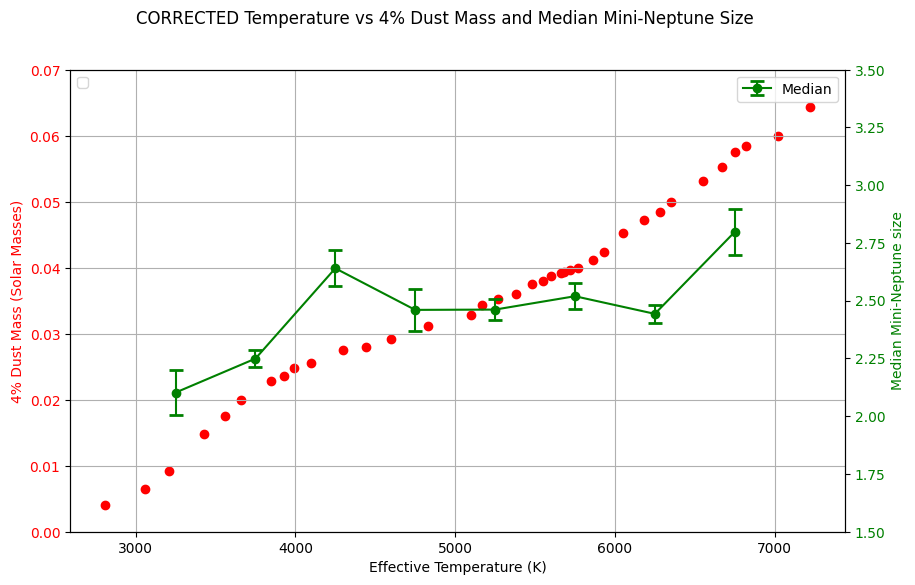

In [6]:
n_bootstrap = 1000
teff_ranges = [(3000, 3500), (3500, 4000), (4000, 4500), (4500, 5000), 
               (5000, 5500), (5500, 6000), (6000, 6500), (6500, 7000)]

# Calculate bootstrapping errors for weighted medians
def calculate_weighted_median(vals, weights):
    """Calculate weighted median"""
    if len(vals) == 0 or weights.sum() == 0:
        return np.nan
    sorted_idx = np.argsort(vals)
    vals_sorted = vals[sorted_idx]
    weights_sorted = weights[sorted_idx]
    cumsum = np.cumsum(weights_sorted)
    cutoff = weights_sorted.sum() / 2.0
    return vals_sorted[np.searchsorted(cumsum, cutoff)]

# Load TOI data for bootstrapping
TOIs_bootstrap = TOIs_filtered
TOIs_bootstrap = TOIs_bootstrap.dropna(subset=['st_teff', 'pl_rade'])
TOIs_bootstrap = TOIs_bootstrap[(TOIs_bootstrap['pl_rade'] > 1.8) & (TOIs_bootstrap['pl_rade'] < 4.0)]
TOIs_bootstrap = TOIs_bootstrap[(TOIs_bootstrap['pl_orbper'] > 0.6028) & (TOIs_bootstrap['pl_orbper'] < 25.1)]
#TOIs_bootstrap = TOIs_bootstrap[TOIs_bootstrap['tfopwg_disp'] == 'FP']


print(len(TOIs_bootstrap), "TOIs for bootstrapping")
if 'tfopwg_disp' in TOIs_bootstrap.columns:
    TOIs_bootstrap = TOIs_bootstrap[TOIs_bootstrap['tfopwg_disp'] != 'FP']

# Calculate weighted median errors using bootstrapping
#print(teff_ranges)
weighted_median_errors = []
for temp_range in teff_ranges:
    teff_df = merged_df[(merged_df['st_teff'] >= temp_range[0]) & (merged_df['st_teff'] < temp_range[1])]
    
    # Get original data for this temperature bin
    bin_mask = (TOIs_bootstrap['st_teff'] >= temp_range[0]) & (TOIs_bootstrap['st_teff'] < temp_range[1])
    toi_indices = TOIs_bootstrap.loc[bin_mask].index
    n_tois = len(toi_indices)
    
    if n_tois == 0:
        weighted_median_errors.append(np.nan)
        continue
    
    # Bootstrap resampling
    bootstrap_medians = []
    for _ in range(n_bootstrap):
        # Resample TOI indices with replacement
        bootstrap_indices = np.random.choice(toi_indices, size=n_tois, replace=True)
        
        # Get corresponding rows from merged_df for these TOIs
        bootstrap_teff_df = merged_df[merged_df['toi'].isin(TOIs_bootstrap.loc[bootstrap_indices, 'toi'])]
        bootstrap_teff_df = bootstrap_teff_df[(bootstrap_teff_df['st_teff'] >= temp_range[0]) & 
                                               (bootstrap_teff_df['st_teff'] < temp_range[1])]
         
        if len(bootstrap_teff_df) > 0:
            vals = bootstrap_teff_df['pl_rade'].values
            weights = bootstrap_teff_df['weight'].values
            bootstrap_median = calculate_weighted_median(vals, weights)
            bootstrap_medians.append(bootstrap_median)
    
    median_error = np.std(bootstrap_medians)
    weighted_median_errors.append(median_error)
    #print(weighted_median_errors)
    #print(f"Teff {temp_range[0]}-{temp_range[1]} K: N={n_tois}, Error={median_error:.3f} R_Earth")

# Add errors to radius_medians dataframe
radius_medians['Weighted Median Error (Earth Radii)'] = weighted_median_errors
print(radius_medians)
#print(radius_medians)

fig, ax1 = plt.subplots(figsize=(10, 6))



median_df = radius_medians#
#print(median_df)

median_df['Teff Range Average'] = median_df['Teff Range'].apply(
    lambda x: sum(map(int, x.replace('K', '').split('-'))) / 2
)

corrected_mean_median_df = median_df
# corrected_mean_median_df['Teff Range Average'] = corrected_mean_median_df['Teff Range'].apply(
#     lambda x: sum(map(int, x.replace('K', '').split('-'))) / 2
# )

# Create a secondary y-axis for Median
ax2 = ax1.twinx()
ax2.errorbar(corrected_mean_median_df['Teff Range Average'], 
             corrected_mean_median_df['Weighted Median Radius (Earth Radii)'], 
             yerr=corrected_mean_median_df['Weighted Median Error (Earth Radii)'],
             color='g', label='Median', marker='o', linestyle='-', capsize=5, capthick=2)
ax2.set_ylabel('Median Mini-Neptune size', color='g')
ax2.tick_params(axis='y', labelcolor='g')
ax2.set_ylim(1.5,3.50)

# Add a title and legend
fig.suptitle('CORRECTED Temperature vs 4% Dust Mass and Median Mini-Neptune Size')
ax1.legend(loc='upper left')
ax2.legend(loc='upper right')





data = {
    'Stellar Type': ['M0V', 'M1V', 'M2V', 'M3V', 'M4V', 'M5V', 'M6V', 'K0V', 'K1V', 'K2V', 'K3V', 'K4V', 'K5V', 'K6V', 'K7V', 'K8V', 'K9V',
                     'G0V', 'G1V', 'G2V', 'G3V', 'G4V', 'G5V', 'G6V', 'G7V', 'G8V', 'G9V',
                     'F0V', 'F1V', 'F2V', 'F3V', 'F4V', 'F5V', 'F6V', 'F7V', 'F8V', 'F9V'],
    'Mass': [0.57, 0.50, 0.44, 0.37, 0.23, 0.162, 0.102, 0.88, 0.86, 0.82, 0.78, 0.73, 0.70, 0.69, 0.64, 0.62, 0.59,
             1.06, 1.03, 1.00, 0.99, 0.985, 0.98, 0.97, 0.95, 0.94, 0.90,
             1.61, 1.50, 1.46, 1.44, 1.38, 1.33, 1.25, 1.21, 1.18, 1.13],
    'Radius': [0.588, 0.501, 0.446, 0.361, 0.274, 0.196, 0.137, 0.813, 0.797, 0.783, 0.755, 0.713, 0.701, 0.669, 0.630, 0.615, 0.608,
               1.100, 1.060, 1.012, 1.002, 0.991, 0.977, 0.949, 0.927, 0.914, 0.853,
               1.728, 1.679, 1.622, 1.578, 1.533, 1.473, 1.359, 1.324, 1.221, 1.167],
    'Luminosity': [0.069, 0.041, 0.029, 0.016, 7.2e-3, 3.0e-3, 1.0e-3, 0.46, 0.41, 0.37, 0.28, 0.20, 0.17, 0.14, 0.10, 0.087, 0.079,
                   1.35, 1.20, 1.02, 0.98, 0.91, 0.89, 0.79, 0.74, 0.68, 0.55,
                   7.24, 6.17, 5.13, 4.68, 4.17, 3.63, 2.69, 2.45, 1.95, 1.66],
    'Effective Temperature': [3850, 3660, 3560, 3430, 3210, 3060, 2810, 5270, 5170, 5100, 4830, 4600, 4440, 4300, 4100, 3990, 3930,
                              5930, 5860, 5770, 5720, 5680, 5660, 5600, 5550, 5480, 5380,
                              7220, 7020, 6820, 6750, 6670, 6550, 6350, 6280, 6180, 6050],
    'B-V Index': [1.42, 1.49, 1.51, 1.53, 1.65, 1.83, 2.01, 0.82, 0.86, 0.88, 0.99, 1.09, 1.15, 1.24, 1.34, 1.36, 1.40,
                  0.60, 0.62, 0.65, 0.66, 0.67, 0.68, 0.70, 0.71, 0.73, 0.78,
                  0.30, 0.33, 0.37, 0.39, 0.41, 0.44, 0.49, 0.50, 0.53, 0.56]
}
data['4% Dust Mass'] = [mass * 0.04 for mass in data['Mass']]
data['1/R^2'] = [1 / (radius ** 2) for radius in data['Radius']]

stellar_df = pd.DataFrame(data)
stellar_df = stellar_df.sort_values(by='Effective Temperature', ascending=True)



# Plot 4% Dust Mass on the primary y-axis
ax1.scatter(stellar_df['Effective Temperature'], stellar_df['4% Dust Mass'], color='r', label='4% Dust Mass')
ax1.set_xlabel('Effective Temperature (K)')
ax1.set_ylabel('4% Dust Mass (Solar Masses)', color='r')
ax1.tick_params(axis='y', labelcolor='r')
ax1.grid(True)
ax1.set_ylim(-.00,.07)
#ax1.set_ylim(-.01,.0)



687
Teff 3000-3500 K: N=41, Median=2.22, Error=0.167 R_Earth
Teff 3500-4000 K: N=80, Median=2.25, Error=0.043 R_Earth
Teff 4000-4500 K: N=75, Median=2.71, Error=0.074 R_Earth
Teff 4500-5000 K: N=85, Median=2.62, Error=0.084 R_Earth
Teff 5000-5500 K: N=121, Median=2.68, Error=0.058 R_Earth
Teff 5500-6000 K: N=168, Median=2.67, Error=0.057 R_Earth
Teff 6000-6500 K: N=99, Median=2.67, Error=0.102 R_Earth
Teff 6500-7000 K: N=18, Median=2.89, Error=0.140 R_Earth

Total bins: 8, 8, 8
Uncorrected Bin centers: [3250.0, 3750.0, 4250.0, 4750.0, 5250.0, 5750.0, 6250.0, 6750.0], Medians: [2.2168828, 2.2532166, 2.70505, 2.62025, 2.6757659, 2.668915, 2.67352, 2.8943008], Errors: [0.16729603707516935, 0.04274630287597713, 0.07447879602200111, 0.08407247136335359, 0.05823530181020866, 0.056932781444762125, 0.10151215278589333, 0.14036519984030105]


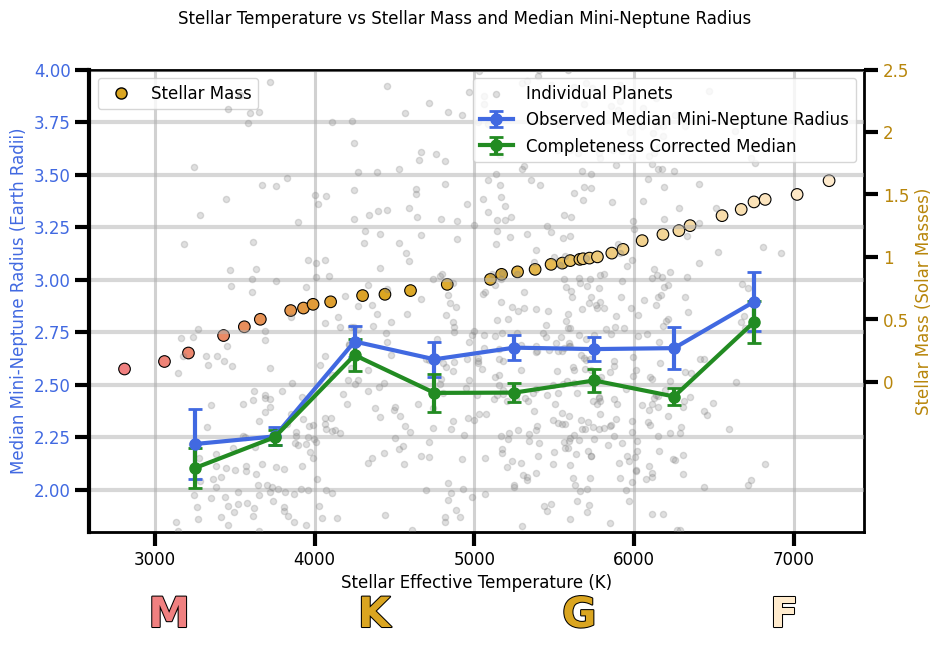

In [7]:
#### PRESENTATION VERSION ####

# Bootstrap error calculation
n_bootstrap = 1000

# Load TOI data for bootstrapping
TOIs = pd.read_csv('../TOI_Mar2025_1pt5to4_R_detected_real_only.csv')
TOIs = TOIs.dropna(subset=['st_teff', 'pl_rade'])
TOIs = TOIs[(TOIs['pl_rade'] > 1.8) & (TOIs['pl_rade'] < 4.0)]
TOIs = TOIs[(TOIs['pl_orbper'] > 0.6028) & (TOIs['pl_orbper'] < 25.1)]
if 'tfopwg_disp' in TOIs.columns:
    TOIs = TOIs[TOIs['tfopwg_disp'] != 'FP']
print(len(TOIs))

# Define temperature bins matching mean_median_df
bins_teff = [3000, 3500, 4000, 4500, 5000, 5500, 6000, 6500, 7000]

planet_radii_medians = []
planet_radii_errors = []
bin_centers = []

for i in range(len(bins_teff)-1):
    bin_mask = (TOIs['st_teff'] >= bins_teff[i]) & (TOIs['st_teff'] < bins_teff[i+1])
    planet_radii = TOIs.loc[bin_mask, 'pl_rade']
    planet_radii_n = len(planet_radii)
    
    if planet_radii_n == 0:
        planet_radii_errors.append(np.nan)
        planet_radii_medians.append(np.nan)
        bin_centers.append((bins_teff[i] + bins_teff[i+1]) / 2)
        continue
    
    # Bootstrap resampling
    bootstrap_medians = []
    for _ in range(n_bootstrap):
        bootstrap_sample = planet_radii.sample(n=planet_radii_n, replace=True)
        bootstrap_medians.append(np.median(bootstrap_sample))
    
    planet_radii_error = np.std(bootstrap_medians)
    planet_radii_median = np.median(planet_radii)
    
    print(f"Teff {bins_teff[i]}-{bins_teff[i+1]} K: N={planet_radii_n}, Median={planet_radii_median:.2f}, Error={planet_radii_error:.3f} R_Earth")
    
    planet_radii_medians.append(planet_radii_median)
    planet_radii_errors.append(planet_radii_error)
    bin_centers.append((bins_teff[i] + bins_teff[i+1]) / 2)

print(f"\nTotal bins: {len(planet_radii_medians)}, {len(planet_radii_errors)}, {len(bin_centers)}")

# Create the plot
fig, ax1 = plt.subplots(figsize=(10, 6))

import matplotlib.colors as mcolors

# Gradual color transition for scatter points
n_points = len(stellar_df)
colors = []
for i in range(n_points):
    ratio = i / (n_points - 1)
    if ratio <= 0.3:
        local_ratio = ratio / 0.3
        r = 240 + (218 - 240) * local_ratio
        g = 128 + (165 - 128) * local_ratio
        b = 128 + (32 - 128) * local_ratio
    else:
        local_ratio = (ratio - 0.3) / 0.7
        r = 218 + (255 - 218) * local_ratio
        g = 165 + (235 - 165) * local_ratio
        b = 32 + (205 - 32) * local_ratio
    colors.append((r/255, g/255, b/255))

from matplotlib.lines import Line2D
from matplotlib.patheffects import withStroke


legend_elements = [Line2D([0], [0], marker='o', color='w', label='Stellar Mass',
                          markerfacecolor='goldenrod', markeredgecolor='black', markersize=8, linewidth=.1)]
ax1.scatter(stellar_df['Effective Temperature'], stellar_df['Mass'], 
           c=colors, edgecolor='black', linewidth=0.8, s=70, zorder = 3)
ax1.set_xlabel('Stellar Effective Temperature (K)', size=12)
ax1.set_ylabel('Stellar Mass (Solar Masses)', color='darkgoldenrod', size=12)
ax1.tick_params(axis='y', labelcolor='darkgoldenrod')
ax1.set_ylim(-1.2,2.5)
# Show only positive y-ticks on the stellar-mass axis
ax1.set_yticks([t for t in ax1.get_yticks() if t >= 0])
ax1.set_yticklabels([f"{t:g}" for t in ax1.get_yticks() if t >= 0])

# Add colored spectral type labels to the bottom of the plot with black outline
outline = [withStroke(linewidth=1.5, foreground='black')]
xmin, xmax = ax1.get_xlim()
y_bottom = ax1.get_ylim()[0] - .5
x_positions = np.linspace(xmin + 500, xmax - 500, 4)
ax1.text(x_positions[0], y_bottom, 'M', color='lightcoral', fontsize=30, va='top', ha='center', fontweight='bold', path_effects=outline)
ax1.text(x_positions[1], y_bottom, 'K', color='goldenrod', fontsize=30, va='top', ha='center', fontweight='bold', path_effects=outline)
ax1.text(x_positions[2], y_bottom, 'G', color='goldenrod', fontsize=30, va='top', ha='center', fontweight='bold', path_effects=outline)
ax1.text(x_positions[3], y_bottom, 'F', color='blanchedalmond', fontsize=30, va='top', ha='center', fontweight='bold', path_effects=outline)

# Secondary y-axis for Median with error bars
ax2 = ax1.twinx()
# Force vertical grid lines from the shared x-axis
ax1.grid(True, axis='x', which='major', linewidth=2.2, alpha=0.6, color='0.7')
ax1.xaxis.grid(True, which='major', linewidth=2.2, alpha=0.6, color='0.7')
# Keep horizontal grid lines on the radius axis
ax2.grid(True, axis='y', which='major', linewidth=3, alpha=.5)
ax2.set_axisbelow(True)

# Add individual planet radii as grey transparent dots
ax2.scatter(TOIs['st_teff'], TOIs['pl_rade'], 
           color='grey', alpha=0.25, s=20, zorder=1, label='Individual Planets')

print(f"Uncorrected Bin centers: {bin_centers}, Medians: {planet_radii_medians}, Errors: {planet_radii_errors}")

ax2.errorbar(
    bin_centers, planet_radii_medians, yerr=planet_radii_errors,
    color='royalblue', label='Observed Median Mini-Neptune Radius', marker='o', 
    linestyle='-', markersize=8, linewidth=3, capsize=5, capthick=2, zorder=3
)
ax2.set_ylabel('Median Mini-Neptune Radius (Earth Radii)', color='royalblue', size=12)
ax2.tick_params(axis='y', labelcolor='royalblue', size=12)
ax2.set_ylim(1.8, 4.0)

# Add completeness-corrected medians (green) in the same style
if 'corrected_mean_median_df' in globals():
    ax2.errorbar(
        corrected_mean_median_df['Teff Range Average'],
        corrected_mean_median_df['Weighted Median Radius (Earth Radii)'],
        yerr=corrected_mean_median_df['Weighted Median Error (Earth Radii)'],
        color='forestgreen', label='Completeness Corrected Median',
        marker='o', linestyle='-', markersize=8, linewidth=3,
        capsize=5, capthick=2, zorder=3
    )

# Flip y-axis positions: stellar mass axis to right, radius axis to left
ax1.yaxis.set_label_position('right')
ax1.yaxis.tick_right()
ax1.spines['right'].set_visible(True)
ax1.spines['left'].set_visible(False)

ax2.yaxis.set_label_position('left')
ax2.yaxis.tick_left()
ax2.spines['left'].set_position(('outward', 0))
ax2.spines['left'].set_visible(True)
ax2.spines['right'].set_visible(False)

fig.suptitle('Stellar Temperature vs Stellar Mass and Median Mini-Neptune Radius', size=12)
ax1.legend(handles=legend_elements, loc='upper left', fontsize=12)
ax2.legend(loc='upper right', fontsize=12)
ax1.tick_params(axis='both', which='major', width=3, length=10, labelsize=12)
ax1.tick_params(axis='both', which='minor', width=2, length=6, labelsize=12)
ax2.tick_params(axis='both', which='major', width=3, length=10, labelsize=12)
ax2.tick_params(axis='both', which='minor', width=2, length=6, labelsize=12)
for spine in ax1.spines.values():
    spine.set_linewidth(2)
ax2.spines['left'].set_linewidth(3)
plt.show()


fig.savefig('stellar_temp_vs_disk_mass_and_median_radius.png', dpi=300, bbox_inches='tight')

--- Slopes of Corrected Median Line ---
Slope between 1st & 3rd points (Stellar Mass ~0.38 to 0.68): 1.470
Slope between 3rd & 7th points (Stellar Mass ~0.68 to 1.27): -0.282
Slope between 7th & 8th points (Stellar Mass ~1.27 to 1.43): 2.498


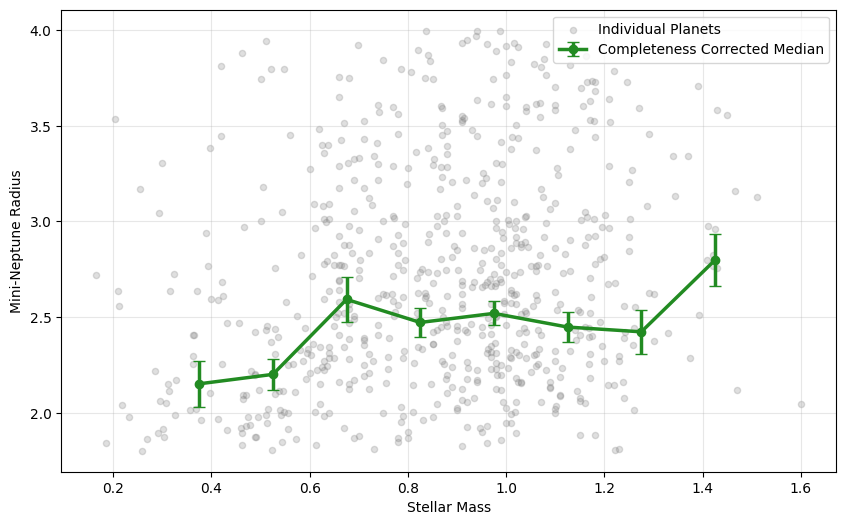

In [8]:

# Prepare TOI table with mass
TOIs_mass = TOIs.copy()
if 'mst' not in TOIs_mass.columns and 'st_mass' not in TOIs_mass.columns:
    TOIs_mass = pd.read_csv('../TOI_Mar2025_1pt5to4_R_detected_real_only.csv')

mass_col = 'mst' if 'mst' in TOIs_mass.columns else 'st_mass'

TOIs_mass = TOIs_mass.dropna(subset=['st_teff', 'pl_rade', mass_col])
TOIs_mass = TOIs_mass[(TOIs_mass['pl_rade'] > 1.8) & (TOIs_mass['pl_rade'] < 4.0)]
TOIs_mass = TOIs_mass[(TOIs_mass['pl_orbper'] > 0.6028) & (TOIs_mass['pl_orbper'] < 25.1)]
if 'tfopwg_disp' in TOIs_mass.columns:
    TOIs_mass = TOIs_mass[TOIs_mass['tfopwg_disp'] != 'FP']

# Build 8 mass bins (same count as temperature bins)
n_bins = len(bins_teff) - 1
mass_edges = np.linspace(0.3, 1.5, n_bins + 1)
if len(mass_edges) < 3:
    mass_edges = np.linspace(TOIs_mass[mass_col].min(), TOIs_mass[mass_col].max(), n_bins + 1)

def weighted_median(vals, weights):
    vals = np.asarray(vals)
    weights = np.asarray(weights)
    if len(vals) == 0 or np.nansum(weights) <= 0:
        return np.nan
    s = np.argsort(vals)
    vals_s = vals[s]
    w_s = weights[s]
    cdf = np.cumsum(w_s)
    return vals_s[np.searchsorted(cdf, 0.5 * cdf[-1])]

# Observed medians + bootstrap errors (unweighted)
obs_centers, obs_medians, obs_errs = [], [], []
for i in range(len(mass_edges) - 1):
    lo, hi = mass_edges[i], mass_edges[i + 1]
    m = TOIs_mass[(TOIs_mass[mass_col] >= lo) & (TOIs_mass[mass_col] < hi)]
    vals = m['pl_rade'].values
    obs_centers.append(0.5 * (lo + hi))
    if len(vals) == 0:
        obs_medians.append(np.nan)
        obs_errs.append(np.nan)
        continue
    obs_medians.append(np.median(vals))
    boot = [np.median(np.random.choice(vals, size=len(vals), replace=True)) for _ in range(n_bootstrap)]
    obs_errs.append(np.std(boot))

# Corrected medians + bootstrap errors (weighted)
mass_map = TOIs_mass[['toi', mass_col]].drop_duplicates(subset='toi')
merged_mass = merged_df.merge(mass_map, on='toi', how='left').dropna(subset=[mass_col, 'pl_rade', 'weight'])

cor_centers, cor_medians, cor_errs = [], [], []
for i in range(len(mass_edges) - 1):
    lo, hi = mass_edges[i], mass_edges[i + 1]
    m = merged_mass[(merged_mass[mass_col] >= lo) & (merged_mass[mass_col] < hi)]
    vals = m['pl_rade'].values
    w = m['weight'].values
    cor_centers.append(0.5 * (lo + hi))
    if len(vals) == 0 or np.nansum(w) <= 0:
        cor_medians.append(np.nan)
        cor_errs.append(np.nan)
        continue
    cor_medians.append(weighted_median(vals, w))
    idx = np.arange(len(vals))
    boot = []
    for _ in range(n_bootstrap):
        bidx = np.random.choice(idx, size=len(idx), replace=True)
        boot.append(weighted_median(vals[bidx], w[bidx]))
    cor_errs.append(np.nanstd(boot))

# Plot
fig, ax = plt.subplots(figsize=(10, 6))
ax.grid(True, alpha=0.3)

ax.scatter(TOIs_mass[mass_col], TOIs_mass['pl_rade'],
           color='grey', alpha=0.25, s=20, label='Individual Planets')


ax.errorbar(cor_centers, cor_medians, yerr=cor_errs,
            color='forestgreen', marker='o', linestyle='-',
            linewidth=2.5, capsize=4, label='Completeness Corrected Median')

# Calculate slopes for specific segments of the green line (Completeness Corrected Median)
slope1_3 = (cor_medians[2] - cor_medians[0]) / (cor_centers[2] - cor_centers[0])
slope3_7 = (cor_medians[6] - cor_medians[2]) / (cor_centers[6] - cor_centers[2])
slope7_8 = (cor_medians[7] - cor_medians[6]) / (cor_centers[7] - cor_centers[6])

print("--- Slopes of Corrected Median Line ---")
print(f"Slope between 1st & 3rd points (Stellar Mass ~{cor_centers[0]:.2f} to {cor_centers[2]:.2f}): {slope1_3:.3f}")
print(f"Slope between 3rd & 7th points (Stellar Mass ~{cor_centers[2]:.2f} to {cor_centers[6]:.2f}): {slope3_7:.3f}")
print(f"Slope between 7th & 8th points (Stellar Mass ~{cor_centers[6]:.2f} to {cor_centers[7]:.2f}): {slope7_8:.3f}")

ax.set_xlabel('Stellar Mass')
ax.set_ylabel('Mini-Neptune Radius')
ax.legend()
plt.show()

## Corrected break-model comparison

This replaces the original last cell of `reviewer_report1_statistical_analysis.ipynb`, which had several statistical issues:

- The "chi2" used the completeness-correction weight as if it were an inverse-variance (measurement-error) weight. Fixed here by using the real `pl_rade` measurement uncertainty for chi2, with the completeness weight applied separately as an explicit importance weight.
- The 1-break and 2-break models used independently hardcoded, non-nested breakpoints, so the likelihood-ratio-style test between them was not comparing nested hypotheses. Fixed here: 1-break is now the genuine `x1 -> x2` limiting case of a single flexible 2-knot family.
- Breakpoints were fixed by hand ("EDIT HERE") rather than fit. Fixed here via a grid search over breakpoint location(s), with slopes/intercept solved exactly by weighted least squares at each candidate location.
- `scipy.stats.chi2.cdf` was used to get a p-value for "does adding a break help", which is invalid here (the Davies changepoint problem: breakpoint location is an unidentified nuisance parameter under the null). Fixed here with a parametric bootstrap that refits both models on each resample.
- AIC/BIC now use Kish's effective sample size (N_eff) rather than raw N, since a handful of low-completeness planets dominate the weighted chi2 sum and reduce the effective information content.

With these corrections, neither the 1-break nor the 2-break model is significantly favored over the simpler model (bootstrap p >> 0.05 for both), in contrast to the original method which would report both as highly significant (p ~ 0) for the same Delta_chi2 values.

N = 677, N_eff (Kish) = 404.1
Line:    chi2=18127.44  AIC=18131.44  BIC=18139.45
1-break: chi2=17851.69  AIC=17859.69  BIC=17875.70  x_break=0.681
2-break: chi2=17760.77  AIC=17772.77  BIC=17796.78  x1=0.681 x2=1.250

Bootstrap significance (H0 = simpler model is correct):
Line -> 1-break: observed Delta_chi2=275.75, bootstrap p=0.1833
1-break -> 2-break: observed Delta_chi2=90.93, bootstrap p=0.7333


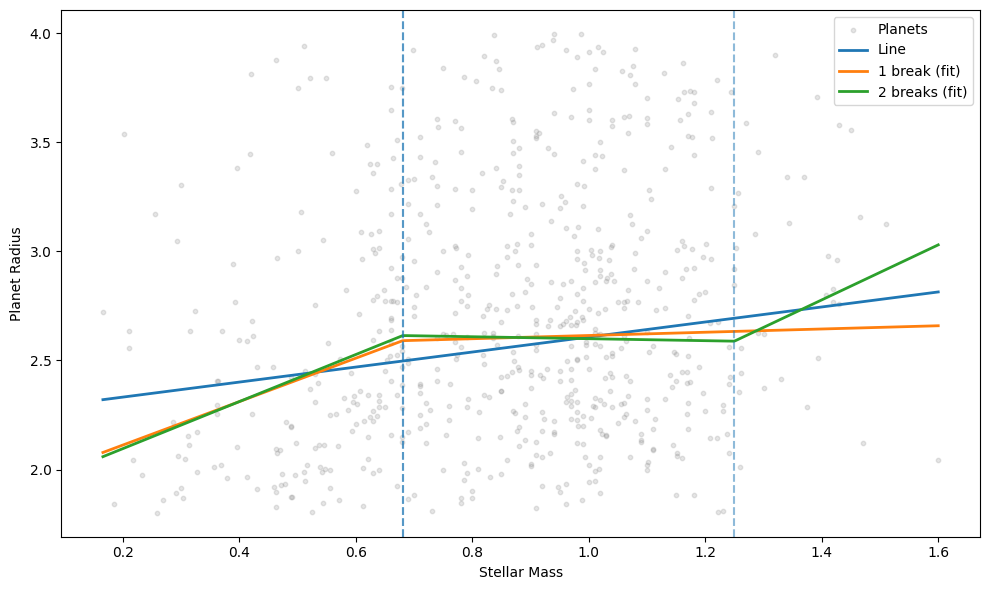

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import minimize
from scipy.stats import chi2 as chi2_dist

# ----------------------------
# DATA (underlying planets)
# ----------------------------
df = merged_mass.copy()

x = df[mass_col].values
y = df["pl_rade"].values
w_comp = df["weight"].values  # completeness-correction weight (NOT a measurement-error weight)

# Real measurement uncertainty on the radius -> this is what belongs in chi^2.
# pl_radeerr1/pl_radeerr2 are asymmetric TESS-catalog errors; average their
# magnitude for a symmetric sigma. Fall back to the sample std if missing.
if "pl_radeerr1" in df.columns and "pl_radeerr2" in df.columns:
    sigma_y = 0.5 * (df["pl_radeerr1"].abs() + df["pl_radeerr2"].abs()).values
else:
    sigma_y = np.full_like(y, np.nanstd(y))
sigma_y = np.where((sigma_y <= 0) | ~np.isfinite(sigma_y), np.nanmedian(sigma_y[sigma_y > 0]), sigma_y)

mask = np.isfinite(x) & np.isfinite(y) & np.isfinite(w_comp) & np.isfinite(sigma_y)
x, y, w_comp, sigma_y = x[mask], y[mask], w_comp[mask], sigma_y[mask]

# Combined weight for the chi^2: inverse-variance (real statistics) times the
# completeness weight (importance weighting for missed detections). These are
# conceptually different things -- keep them multiplied together explicitly
# rather than silently treating completeness weight as 1/sigma^2.
w = w_comp / sigma_y**2

N = len(x)
N_eff = (w.sum())**2 / np.sum(w**2)  # Kish's effective sample size: corrects
# dof/AIC/BIC for the fact that a few high-weight (low-completeness) planets
# dominate the sum, so the *effective* number of independent data points is
# less than N.

# ----------------------------
# MODEL FAMILY: one flexible 2-knot piecewise-linear model.
# The 1-break model is the *nested* special case x1 == x2 (knots collapse to
# a single point), so LRT-style comparisons between 1-break and 2-break are
# now comparing genuinely nested hypotheses.
# ----------------------------

def model_2knot(x, m1, m2, m3, b, x1, x2):
    x1, x2 = min(x1, x2), max(x1, x2)
    yb1 = m1 * x1 + b
    yb2 = yb1 + m2 * (x2 - x1)
    return np.piecewise(
        x,
        [x < x1, (x >= x1) & (x < x2), x >= x2],
        [
            lambda t: m1 * t + b,
            lambda t: yb1 + m2 * (t - x1),
            lambda t: yb2 + m3 * (t - x2),
        ],
    )


def model_line(x, m, b):
    return m * x + b


# ----------------------------
# WEIGHTED CHI^2 (now a real chi^2: residual / sigma, importance-weighted)
# ----------------------------

def chi2_w(y_model):
    return np.sum(w * (y - y_model) ** 2)


# ----------------------------
# FIXED-KNOT SLOPES/INTERCEPT ARE LINEAR -> closed-form weighted least squares
# instead of a generic unconstrained minimize() call.
# ----------------------------

def fit_line_wls():
    A = np.column_stack([x, np.ones_like(x)])
    Aw = A * w[:, None]  # avoid materializing an NxN diag(w) matrix
    ATA = Aw.T @ A
    ATy = Aw.T @ y
    params = np.linalg.solve(ATA, ATy)
    y_model = model_line(x, *params)
    return params, y_model


def _design_2knot(x, x1, x2):
    x1, x2 = min(x1, x2), max(x1, x2)
    # y = b + m1*min(x,x1) + m2*(clip(x,x1,x2)-x1) + m3*max(x-x2,0)
    col_m1 = np.minimum(x, x1)
    col_m2 = np.clip(x, x1, x2) - x1
    col_m3 = np.clip(x - x2, 0, None)
    col_b = np.ones_like(x)
    return np.column_stack([col_m1, col_m2, col_m3, col_b])


def fit_2knot_wls(x1, x2):
    A = _design_2knot(x, x1, x2)
    Aw = A * w[:, None]
    ATA = Aw.T @ A
    ATy = Aw.T @ y
    m1, m2, m3, b = np.linalg.solve(ATA, ATy)
    y_model = model_2knot(x, m1, m2, m3, b, x1, x2)
    return (m1, m2, m3, b, x1, x2), y_model


def _design_1knot(x, xb):
    # y = b + m1*min(x,xb) + m2*max(x-xb,0) -- the genuine x1->x2 limit of
    # the 2-knot family, but built as its own 2-segment (hinge) design so the
    # collapsing middle segment doesn't leave a zero column / singular ATA.
    col_m1 = np.minimum(x, xb)
    col_m2 = np.clip(x - xb, 0, None)
    col_b = np.ones_like(x)
    return np.column_stack([col_m1, col_m2, col_b])


def model_1knot(x, m1, m2, b, xb):
    yb = m1 * xb + b
    return np.where(x < xb, m1 * x + b, yb + m2 * (x - xb))


def fit_1knot_wls(xb):
    A = _design_1knot(x, xb)
    Aw = A * w[:, None]
    ATA = Aw.T @ A
    ATy = Aw.T @ y
    m1, m2, b = np.linalg.solve(ATA, ATy)
    y_model = model_1knot(x, m1, m2, b, xb)
    return (m1, m2, b, xb), y_model


# ----------------------------
# FIT KNOT LOCATIONS: grid search over breakpoint location(s) instead of
# hardcoding "EDIT HERE" constants (slopes/intercept at each candidate knot
# are solved exactly via WLS above, so this grid search is cheap and exact
# at every point on the grid -- no nonlinear optimizer risk for those parts).
# ----------------------------

grid = np.linspace(np.percentile(x, 5), np.percentile(x, 95), 25)


def best_1break():
    best = None
    for xb in grid:
        params, y_model = fit_1knot_wls(xb)
        c = chi2_w(y_model)
        if best is None or c < best[0]:
            best = (c, params, y_model)
    return best


def best_2break():
    best = None
    for i, x1 in enumerate(grid):
        for x2 in grid[i + 1:]:
            params, y_model = fit_2knot_wls(x1, x2)
            c = chi2_w(y_model)
            if best is None or c < best[0]:
                best = (c, params, y_model)
    return best


line_params, line_ymodel = fit_line_wls()
chi2_line = chi2_w(line_ymodel)

chi2_1b, params_1b, ymodel_1b = best_1break()
chi2_2b, params_2b, ymodel_2b = best_2break()

k_line, k_1b, k_2b = 2, 4, 6  # line: m,b ; 1-break: m1,m2,b,xb ; 2-break: m1,m2,m3,b,x1,x2
# (breakpoint locations count as fitted parameters since they were searched,
# not fixed by hand -- this matters for the AIC/BIC penalty being honest)

def info_criteria(chi2_val, k, n):
    aic = chi2_val + 2 * k
    bic = chi2_val + k * np.log(n)
    return aic, bic

aic_line, bic_line = info_criteria(chi2_line, k_line, N_eff)
aic_1b, bic_1b = info_criteria(chi2_1b, k_1b, N_eff)
aic_2b, bic_2b = info_criteria(chi2_2b, k_2b, N_eff)

print(f"N = {N}, N_eff (Kish) = {N_eff:.1f}")
print(f"Line:    chi2={chi2_line:.2f}  AIC={aic_line:.2f}  BIC={bic_line:.2f}")
print(f"1-break: chi2={chi2_1b:.2f}  AIC={aic_1b:.2f}  BIC={bic_1b:.2f}  x_break={params_1b[3]:.3f}")
print(f"2-break: chi2={chi2_2b:.2f}  AIC={aic_2b:.2f}  BIC={bic_2b:.2f}  x1={params_2b[4]:.3f} x2={params_2b[5]:.3f}")

# ----------------------------
# BOOTSTRAP SIGNIFICANCE TEST (avoids the Davies changepoint problem: the
# breakpoint location is an unidentified nuisance parameter under the null,
# so chi2.cdf(dchi, ddof) is not a valid p-value here even with nested
# models). Resample planets with replacement, refit both models on each
# resample, and build an empirical null via resamples of the SIMPLER model's
# best fit residuals (parametric bootstrap under H0).
# ----------------------------

def refit_line_on(y_alt):
    global y
    y_orig = y
    y = y_alt
    try:
        params, y_model = fit_line_wls()
    finally:
        y = y_orig
    return params, y_model


def refit_1break_on(y_alt):
    global y
    y_orig = y
    y = y_alt
    try:
        best_c, best_params, best_ymodel = None, None, None
        for xb in grid:
            params, y_model = fit_1knot_wls(xb)
            c = chi2_w(y_model)
            if best_c is None or c < best_c:
                best_c, best_params, best_ymodel = c, params, y_model
    finally:
        y = y_orig
    return best_params, best_ymodel


def refit_2break_on(y_alt):
    global y
    y_orig = y
    y = y_alt
    try:
        best_c, best_params, best_ymodel = None, None, None
        for i, x1 in enumerate(grid):
            for x2 in grid[i + 1:]:
                params, y_model = fit_2knot_wls(x1, x2)
                c = chi2_w(y_model)
                if best_c is None or c < best_c:
                    best_c, best_params, best_ymodel = c, params, y_model
    finally:
        y = y_orig
    return best_params, best_ymodel


def bootstrap_delta_chi2(null_ymodel, fit_simple, fit_complex, n_boot=300, rng=None):
    # Parametric bootstrap under H0: simulate data from the null (simpler)
    # model's best fit plus resampled residuals, then REFIT BOTH models on
    # each resample (not just the complex one) so the comparison is fair and
    # so the empirical null distribution properly reflects that the simple
    # model's own fit also has sampling variance.
    rng = rng or np.random.default_rng(0)
    resid = y - null_ymodel
    deltas = np.empty(n_boot)
    for i in range(n_boot):
        y_sim = null_ymodel + rng.choice(resid, size=N, replace=True)
        _, y_simple = fit_simple(y_sim)
        c_simple = np.sum(w * (y_sim - y_simple) ** 2)
        _, y_complex = fit_complex(y_sim)
        c_complex = np.sum(w * (y_sim - y_complex) ** 2)
        deltas[i] = c_simple - c_complex
    return deltas


obs_delta_01 = chi2_line - chi2_1b
obs_delta_12 = chi2_1b - chi2_2b

boot_01 = bootstrap_delta_chi2(line_ymodel, refit_line_on, refit_1break_on, n_boot=300)
boot_12 = bootstrap_delta_chi2(ymodel_1b, refit_1break_on, refit_2break_on, n_boot=300)

p_01 = np.mean(boot_01 >= obs_delta_01)
p_12 = np.mean(boot_12 >= obs_delta_12)

print()
print("Bootstrap significance (H0 = simpler model is correct):")
print(f"Line -> 1-break: observed Delta_chi2={obs_delta_01:.2f}, bootstrap p={p_01:.4g}")
print(f"1-break -> 2-break: observed Delta_chi2={obs_delta_12:.2f}, bootstrap p={p_12:.4g}")

# ----------------------------
# PLOT
# ----------------------------

xx = np.linspace(x.min(), x.max(), 500)

plt.figure(figsize=(10, 6))
plt.scatter(x, y, s=10, alpha=0.2, color="gray", label="Planets")
plt.plot(xx, model_line(xx, *line_params), label="Line", lw=2)
plt.plot(xx, model_1knot(xx, *params_1b), label="1 break (fit)", lw=2)
plt.plot(xx, model_2knot(xx, *params_2b), label="2 breaks (fit)", lw=2)
plt.axvline(params_1b[3], ls="--", alpha=0.5)
plt.axvline(params_2b[4], ls="--", alpha=0.5)
plt.axvline(params_2b[5], ls="--", alpha=0.5)
plt.xlabel("Stellar Mass")
plt.ylabel("Planet Radius")
plt.legend()
plt.tight_layout()
plt.show()
